# Segmentation: Split Floes
In most images, at least some floes will be in contact, so floe splitting methods are necessary to separate objects for labeling. 

* Opening (erosion followed by dilation, single pass). Stern et al. 2018 used 1 or 2 pixel erosions.
* Watershed transformation. Watershed transforms require markers
* Erosion-propagation. Methods differ on how to reconstruct floes after erosion.
  * Paget et al. 2001 check the 8-neighborhood and assign to nearest.
* Erosion-expansion
  * Buckley et al. method: iterative erosion-expansion, removing detected floes, and using watershed transformation for final border expansion.

Our new method aims to 



## TODO
Run experiment on all floe data, do test/train split in Python at visualization stage to set area-dependent limits on erosion-expansion.

In [1]:
using Pkg
Pkg.activate("../scripts/calval/")
using IceFloeTracker
using Images

dataset = Watkins2026Dataset(; ref="v0.2")

  Activating project at `~/Documents/research/calval_tgrs/scripts/calval`


Dataset(GitHubLoader("https://github.com/danielmwatkins/ice-floe-validation-dataset", "v0.2", "/tmp/Watkins2026"), 378×26 DataFrame
 Row │        case_number  region          satellite  start_date  pass_time    ⋯
     │ Int64  Int64        String          String     Dates.Date  DateTime     ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │     0            1  baffin_bay      terra      2022-09-11  2022-09-11T1 ⋯
   2 │     1            1  baffin_bay      aqua       2022-09-11  2022-09-11T1
   3 │     2            2  baffin_bay      terra      2015-03-12  2015-03-12T1
   4 │     3            2  baffin_bay      aqua       2015-03-12  2015-03-12T1
   5 │     4            3  baffin_bay      terra      2012-04-19  2012-04-19T1 ⋯
   6 │     5            3  baffin_bay      aqua       2012-04-19  2012-04-19T1
   7 │     6            4  baffin_bay      terra      2019-09-25  2019-09-25T1
   8 │     7            4  baffin_bay      aqua       2019-09-25  20

In [197]:
cases = filter(r -> r.number_floes > 0, dataset)
tc_imgs = modis_truecolor.(cases)
binary_floes = validated_binary_floes.(cases);
binary_floes .= clearborder.(binary_floes);

## Experiment: Reconstruction of floes after $n$ erosions

We posit that there is a lower limit on size of floes which can be reconstructed without error from erosion-expansion. For i from 1 to 15, we perform i erosions followed by i expansions of a floe mask. The question is: What are the limits for floe reconstruction, assuming an ideal starting point? How many times can we erode a floe before it can't be rebuilt with skill?

,,,,,,,,,,,,,,,,,,,

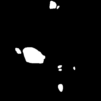
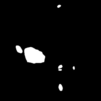
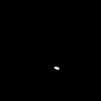
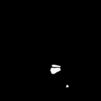
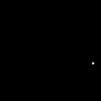
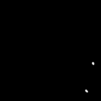
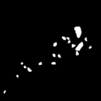
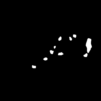
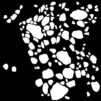
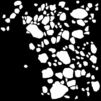
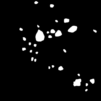
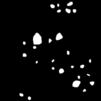
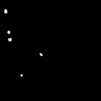
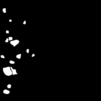
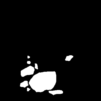
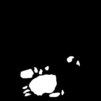
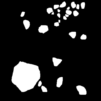
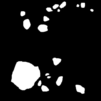
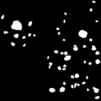
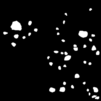

In [202]:
binary_floes[1:20]

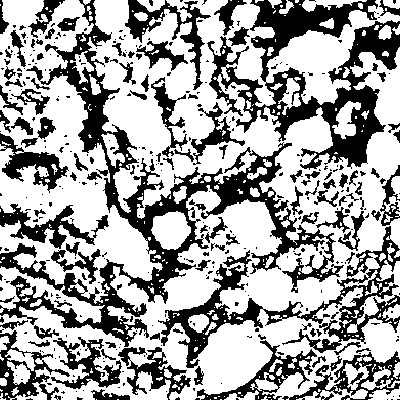

In [219]:
# Gaussian binarization
gray_img = float64.(Gray.(tc_imgs[2 * idx]))
smoothed = imfilter(gray_img, Kernel.gaussian(40))
imbinary_10km = Gray.((gray_img .- smoothed) .> 0)

# cleanup
# imbinary_10km .= erode(imbinary_10km, strel_diamond((3,3))) |> fill_holes |> dilate;

Gray.(imbinary_10km)

In [232]:
function erode_expand(shape; n=1, strel=strel_diamond((3,3)))
    out = copy(shape)
    for i = 1:n
        out .= erode(out, strel)
    end
    for i = 1:n
        out .= dilate(out, strel)
    end
    return out
end

for idx in 1:nrow(cases.info)
    labeled_floes = label_components(clearborder(binary_floes[idx]))
    df = IceFloeTracker.regionprops_table(labeled_floes)
    add_floemasks!(df, labeled_floes);
    
    
    for i in range(1, 10)
        col = "ee_n"*string(i)
        df[:, col] = erode_expand.(df.mask; n=i)
        df[:, col*"_area"] = sum.(df[:, col])
        df[:, col*"_area_err"] = (df[:, "area"] - df[:, col*"_area"]) ./ df[:, "area"]
    end

    cn = lpad(string(cases.info.case_number[idx]), 3, "0")
    sat = cases.info.satellite[idx]
    
    save("../data/erosion_test/"*cn*"_"*sat*".csv", df[:, Not(:mask, ["ee_n"*string(i) for i in 1:10]...)])
end

┌ Warning: Labeled image is empty!
└ @ IceFloeTracker.Segmentation ~/.julia/packages/IceFloeTracker/UZ2Bw/src/Segmentation/regionprops.jl:619
┌ Warning: Labeled image is empty!
└ @ IceFloeTracker.Segmentation ~/.julia/packages/IceFloeTracker/UZ2Bw/src/Segmentation/regionprops.jl:619
┌ Warning: Labeled image is empty!
└ @ IceFloeTracker.Segmentation ~/.julia/packages/IceFloeTracker/UZ2Bw/src/Segmentation/regionprops.jl:619
┌ Warning: Labeled image is empty!
└ @ IceFloeTracker.Segmentation ~/.julia/packages/IceFloeTracker/UZ2Bw/src/Segmentation/regionprops.jl:619
┌ Warning: Labeled image is empty!
└ @ IceFloeTracker.Segmentation ~/.julia/packages/IceFloeTracker/UZ2Bw/src/Segmentation/regionprops.jl:619


erode_propagate (generic function with 1 method)

In [261]:
strel(strel_disk(3)) == strel_disk(3)

true

In [277]:
shuffle([1, 2, 3])

3-element Vector{Int64}:
 2
 3
 1

In [335]:
using StatsBase
using Random

"""
Selection function for Paget et al. method. If no nonzero labels in a, return 0.
Otherwise, return the most common label. If both equally represented, choose one at random.

"""
function f(a)
    if all(a .== 0) 
        return 0
    end

    # # shuffle a, then get mode
    # # the mode function returns the first in case of a tie
    labels = filter(r -> r != 0, unique(a))    
    return mode(shuffle(labels))
end
"""

Label updater for the Paget et al. method. Applies the decision function to the scene
until it stops changing.

"""
function update_labels(mask, labels)
    
    new_labels = copy(labels)
    state_prev = 0
    state_now = sum(new_labels)
    while state_prev != state_now
        state_prev = sum(new_labels)
        new_labels .= mapwindow(f, new_labels, (3,3))
        new_labels[labels .> 0] .= labels[labels .> 0] # retain originals
        new_labels[.!mask] .= 0
        state_now = sum(new_labels)
    end
    return new_labels
end

update_labels

3×3 ImageMorphology.StructuringElements.SEBoxArray{2, UnitRange{Int64}} with indices -1:1×-1:1:
 1  1  1
 1  1  1
 1  1  1

In [340]:
function erode_propagate(mask; n_max = 10, step=1, strel=strel_box((3,3)))
    _mask = mask .> 0
    
    # Pre-allocate
    out = [zeros(Bool, size(mask)) for i=1:n_max]
    for i = 1:step:n_max
        _mask .= erode(_mask, strel)
        out[i][_mask .> 0] .= true
    end

    L = label_components(out[n_max])
    for i = (n_max-1):-step:1
        L .= update_labels(out[i], L)
    end
        
    return L
end


erode_propagate (generic function with 1 method)

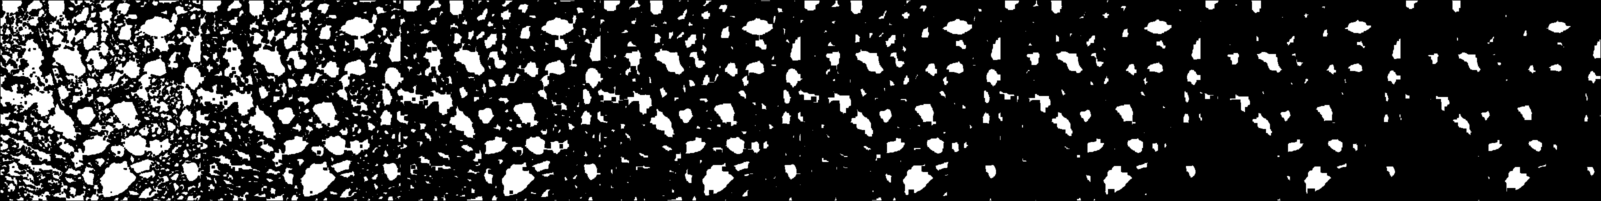

In [336]:
tmp = erode_propagate(bw; n_max=8);
mosaicview([Gray.(r) for r in tmp]..., nrow=1)

In [345]:
L = erode_propagate(bw; n_max=2);

LoadError: InterruptException:

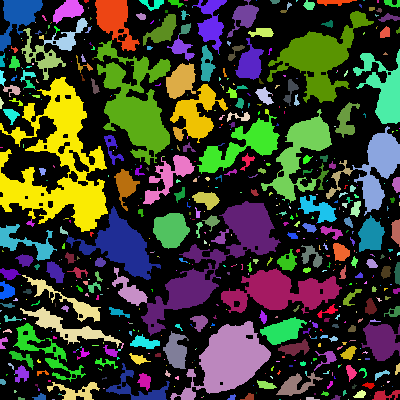

In [346]:
vsr(L)

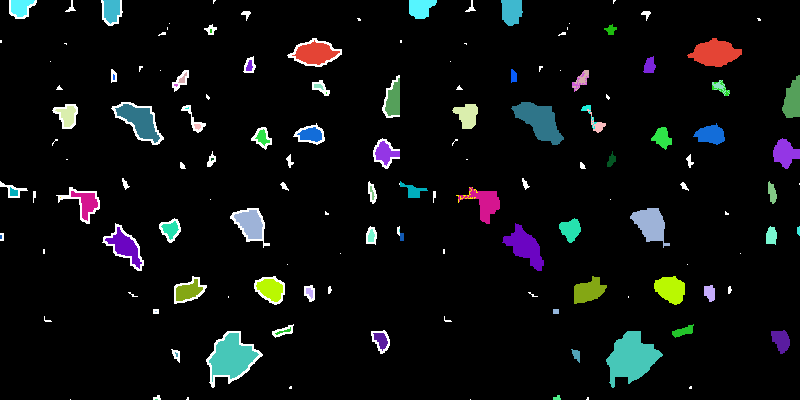

In [339]:
vsr(r) = view_seg_random(SegmentedImage(r, r))
L0 = label_components(tmp[8])
L = update_labels(tmp[6], L0)

prev_labels = RGB.(tmp[6])
prev_labels[tmp[8] .> 0] .= vsr(label_components(tmp[8]))[tmp[8] .> 0]

updated_labels = RGB.(tmp[6])
updated_labels[L .> 0] .= vsr(L)[L .> 0]

mosaicview(prev_labels, updated_labels, nrow=1)

In [338]:
L[190:220, 60:90]

31×31 Matrix{Int64}:
 0  0  0  0  0  0  0  0  0  0  0  6  6  …  0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  0  0  0  0  5  5     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  0  0  0  0  5  6     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  0  0  0  0  6  6     6  6  6  6  6  6  6  6  6  6  6  6
 0  0  0  0  0  0  0  0  0  0  0  6  6     6  6  6  6  6  6  6  6  6  6  6  6
 0  0  0  0  0  0  0  0  0  0  0  5  6  …  6  6  6  6  6  6  6  6  6  6  6  6
 0  0  0  0  0  0  0  0  0  0  0  6  6     6  6  6  6  6  6  6  6  6  6  6  6
 5  6  5  6  5  6  6  5  6  6  6  5  6     6  6  6  6  6  6  6  6  6  6  6  6
 6  5  6  6  6  6  6  6  5  6  6  6  6     6  6  6  6  6  6  6  6  6  6  6  6
 5  6  6  0  0  0  0  0  0  0  0  0  0     0  0  6  6  6  6  6  6  6  6  6  6
 0  0  0  0  0  0  0  0  0  0  0  0  0  …  0  0  6  6  6  6  6  6  6  6  6  6
 0  0  0  0  0  0  0  0  0  0  0  0  0     0  0  6  6  6  6  6  6  6  6  6  6
 0  0  0  0  0  0  0  0  0  0  0  0  0     

In [282]:
A = zeros(Int64, (5,5))
A[3,3] = 1
A[3,5] = 2
A

5×5 Matrix{Int64}:
 0  0  0  0  0
 0  0  0  0  0
 0  0  1  0  2
 0  0  0  0  0
 0  0  0  0  0

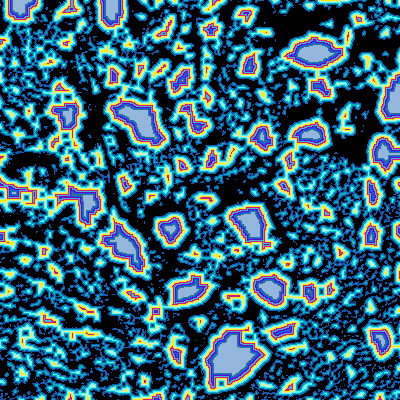

In [235]:
ep_img = erode_propagate(bw)
view_seg_random(SegmentedImage(bw, ep_img))

In [257]:
ep_img = erode_propagate(bw; n_max=20);

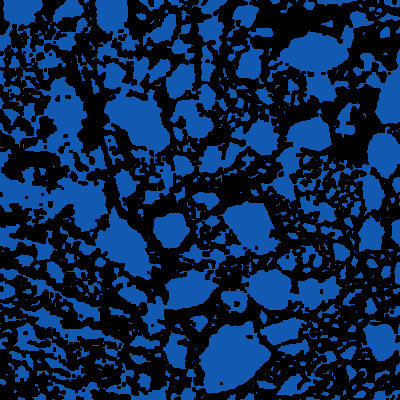

In [258]:
view_seg_random(SegmentedImage(bw, ep_img))

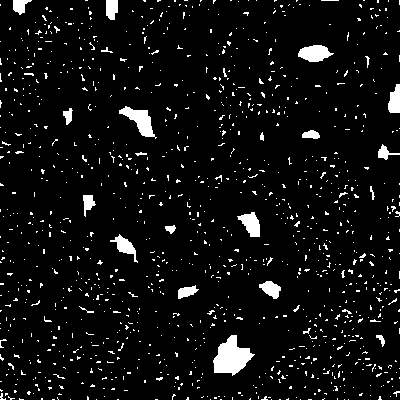

In [236]:
Gray.(local_maxima(ep_img) .> 0)



To update the erosion-expansion method, we return to the methods from the propagation methods. We initially perform a distance transform, and round to the nearest integer to make a stepped image. 

1. Set aside objects smaller than the minimum size
2. check current level. 

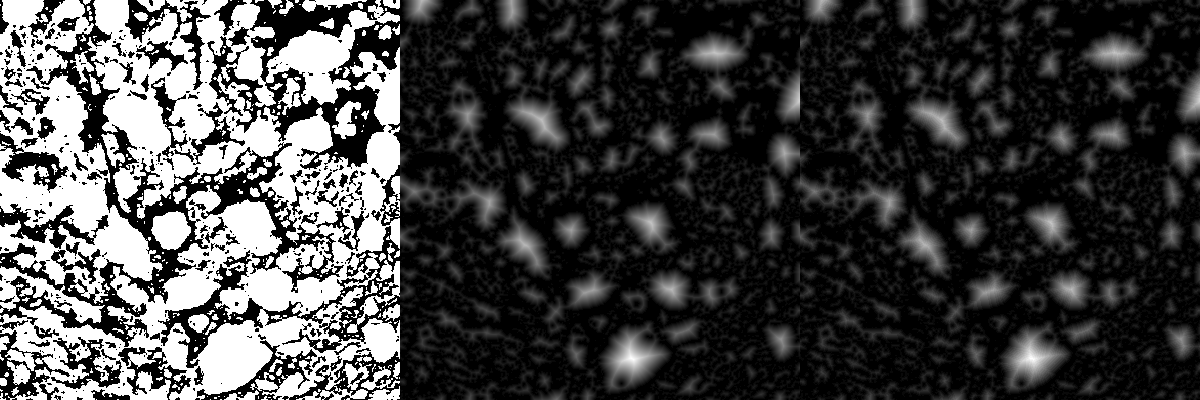

In [222]:
# bw = copy(binary_floes[2 * idx]) .> 0
bw = imbinary_10km .> 0
d = distance_transform(feature_transform(.!bw))
d_stepped = round.(Int64, d)
mosaicview(Gray.(bw), Gray.(d ./ maximum(d)), Gray.(d_stepped ./ maximum(d_stepped)), nrow=1)

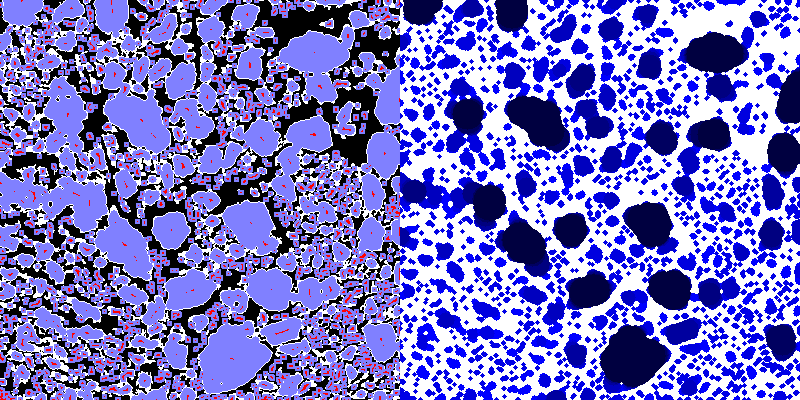

In [223]:
bw_img = RGB.(bw)
examp_img = RGB.(ones(size(bw)))
lmax = local_maxima(d_stepped) # labeled local_maxima
bw_img[dilate(lmax, strel_box((5,5))) .> 0] .= RGB(0.5, 0.5, 1)
examp_img[dilate(lmax .> 0, strel_diamond((5,5)))] .= RGB(0, 0, 0.9)

for dist in [4, 6, 8, 10, 12, 14, 16]
    X = expand_labels(Int64.(d .> dist), dist-1)
    bw_img[X .> 0] .= RGB(0.5, 0.5, 1)
    examp_img[X .> 0] .= RGB(0, 0, 1) * (20 - dist) / 16
end

bw_img[lmax .> 0] .= RGB(1, 0, 0)
mosaicview(bw_img, examp_img, nrow=1)

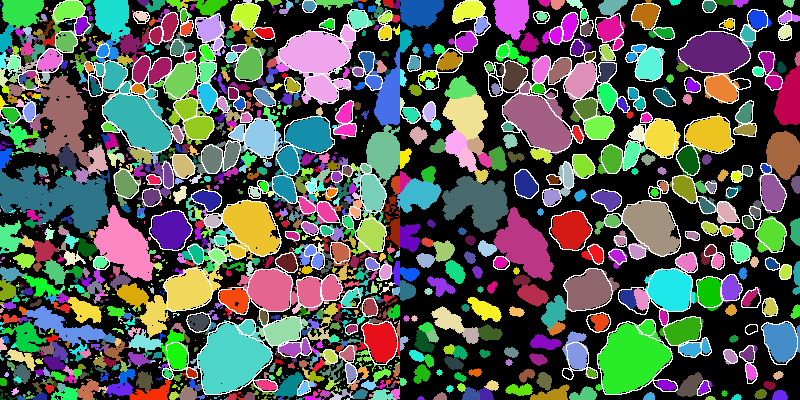

In [233]:
markers = label_components(Gray.(examp_img) .< 1)
seg = watershed(.-d, markers; compactness=2)

ref = binary_floes[2 * idx] .> 0
outlines = dilate(ref) 
outlines[ref .> 0] .= 0

cview = view_seg_random(seg)
cview[bw .== 0] .= RGB(0)
cview[outlines .> 0] .= RGB(1)

dms = SegmentedImage(bw, dist_morph_split(bw))
cview_dms = view_seg_random(dms)
cview_dms[outlines .> 0] .= RGB(1)
mosaicview(cview, cview_dms, nrow=1)

In [189]:
?watershed

search: watershed



```julia
segments                = watershed(img, markers; compactness, mask)
```

Segments the image using watershed transform. Each basin formed by watershed transform corresponds to a segment. If you are using image local minimas as markers, consider using [`hmin_transform`](@ref) to avoid oversegmentation.

Parameters:

  * img            = input grayscale image
  * markers        = An array (same size as img) with each region's marker assigned a index starting from 1. Zero means not a marker.                     If two markers have the same index, their regions will be merged into a single region.                     If you have markers as a boolean array, use `label_components`.
  * compactness    = Use the compact watershed algorithm with the given compactness parameter. Larger values lead to more regularly                     shaped watershed basins.[^1]
  * mask           = Only segment pixels where the value of `mask` is true, used to restrict segmentation to only areas of interest

[^1]: https://www.tu-chemnitz.de/etit/proaut/publications/cws*pSLIC*ICPR.pdf

# Example

```jldoctest; setup = :(using ImageCore, ImageMorphology, ImageSegmentation)
julia> seeds = falses(100, 100); seeds[50, 25] = true; seeds[50, 75] = true;

julia> dists = distance_transform(feature_transform(seeds)); # calculate distances from seeds

julia> markers = label_components(seeds); # give each seed a unique integer id

julia> results = watershed(dists, markers);

julia> labels_map(results); # labels of segmented image
```


In [164]:
maxima_labels = label_components(dilate(lmax, strel_box((5,5))))
df = regionprops_table(maxima_labels; properties=[:label, :area])
expansion_by = segment_mean(SegmentedImage(d, maxima_labels));
df.local_distance = [expansion_by[r] for r in df.label]
df

Row,area,label,local_distance
,Int64,Int64,Float64
1,18,1,6.55621
2,63,2,4.47423
3,58,3,3.68896
4,26,4,16.5637
5,53,5,6.43025
6,30,6,4.47454
7,67,7,7.64136
8,25,8,6.61271
9,48,9,7.44725


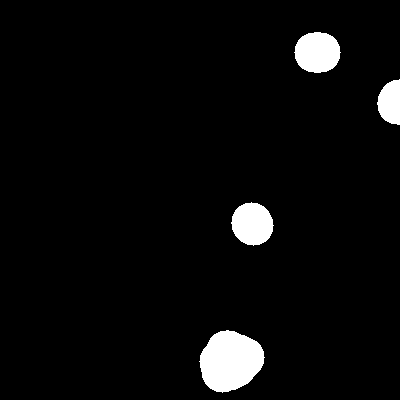

In [157]:
?local_maxima

search: local_maxima local_maxima! local_minima local_minima! findlocalmaxima



```julia
local_maxima(image, [maxtree]; connectivity=1) -> Array
```

Determines and labels all *local maxima* of the `image`.

# Details

The *local maximum* is defined as the connected set of pixels that have the same value, which is greater than the values of all pixels in direct neighborhood of the set.

Technically, the implementation is based on the *max-tree* representation of an image. It's beneficial if the max-tree is already computed, otherwise `ImageFiltering.findlocalmaxima` would be more efficient.

# Arguments

  * `image::GenericGrayImage`: the $N$-dimensional input image
  * `connectivity::Integer=1`: the neighborhood connectivity. The maximum number of orthogonal steps to reach a neighbor of the pixel. In 2D, it is 1 for a 4-neighborhood and 2 for a 8-neighborhood.
  * `maxtree::MaxTree`: optional pre-built *max-tree*. Note that `maxtree` and `connectivity` optional parameters are mutually exclusive.

# Returns

An integer array of the same shape as the `image`. Pixels that are not local maxima have 0 value. Pixels of the same local maximum share the same positive value (the local maximum id).

# See also

[`MaxTree`](@ref), [`local_maxima!`](@ref), [`local_minima`](@ref), `ImageFiltering.findlocalmaxima`

# Examples

Create `f` (quadratic function with a maximum in the center and 4 additional constant maxima):

```jldoctest; setup = :(using ImageMorphology)
julia> w = 10;

julia> f = [20 - 0.2*((x - w/2)^2 + (y-w/2)^2) for x in 0:w, y in 0:w];

julia> f[3:5, 3:5] .= 40; f[3:5, 8:10] .= 60; f[8:10, 3:5] .= 80; f[8:10, 8:10] .= 100;

julia> f_maxima = local_maxima(f); # Get all local maxima of `f`
```

The resulting image contains the 4 labeled local maxima.
